In [1]:
# Etapa 1
# API: WeatherAPI (clima atual)
# Documentação: https://www.weatherapi.com/docs/
from getpass import getpass

import requests

API_KEY = getpass("Digite sua API_KEY: ")
url = "https://api.weatherapi.com/v1/current.json"

cidades = [
    "São Paulo", "Rio de Janeiro", "Belo Horizonte", "Curitiba", "Porto Alegre",
    "Salvador", "Fortaleza", "Manaus", "Brasília", "Recife",
]

Digite sua API_KEY: ··········


In [2]:
# Etapa 2
respostas = []

for cidade in cidades:
    parametros = {"key": API_KEY, "q": cidade + ", Brazil", "lang": "pt"}
    try:
        resposta = requests.get(url, params=parametros, timeout=10)
        print(f"{cidade} - status: {resposta.status_code}")
        resposta.raise_for_status()
        respostas.append(resposta)
    except requests.exceptions.HTTPError:
        print(f"Erro em {cidade}: cidade inválida ou chave incorreta (status {resposta.status_code}).")
    except requests.exceptions.RequestException as erro:
        print(f"Falha de rede em {cidade}: {type(erro).__name__}")

São Paulo - status: 200
Rio de Janeiro - status: 200
Belo Horizonte - status: 200
Curitiba - status: 200
Porto Alegre - status: 200
Salvador - status: 200
Fortaleza - status: 200
Manaus - status: 200
Brasília - status: 200
Recife - status: 200


In [3]:
# Etapa 3
resultados = []

for resposta in respostas:
    resultados.append(resposta.json())

print("Chaves principais:", resultados[0].keys())
print("Chaves de current:", resultados[0]["current"].keys())

for dados in resultados:
    nome = dados["location"]["name"]
    temp = dados["current"]["temp_c"]
    condicao = dados["current"]["condition"]["text"]
    print(f"{nome}: {temp}°C - {condicao}")

Chaves principais: dict_keys(['location', 'current'])
Chaves de current: dict_keys(['last_updated_epoch', 'last_updated', 'temp_c', 'temp_f', 'is_day', 'condition', 'wind_mph', 'wind_kph', 'wind_degree', 'wind_dir', 'pressure_mb', 'pressure_in', 'precip_mm', 'precip_in', 'humidity', 'cloud', 'feelslike_c', 'feelslike_f', 'windchill_c', 'windchill_f', 'heatindex_c', 'heatindex_f', 'dewpoint_c', 'dewpoint_f', 'vis_km', 'vis_miles', 'uv', 'gust_mph', 'gust_kph', 'will_it_rain', 'chance_of_rain', 'will_it_snow', 'chance_of_snow', 'wetbulb_c', 'wetbulb_f', 'short_rad', 'diff_rad', 'dni', 'gti'])
San Paulo: 20.3°C - Chuva passageira fraca
Rio De Janeiro: 24.1°C - Chuva passageira fraca
Belo Horizonte: 27.4°C - Chuva passageira fraca
Curitiba: 18.2°C - Chuva irregular nas proximidades
Porto Alegre: 26.5°C - Ensolarado
Salvador: 29.2°C - Parcialmente nublado
Fortaleza: 38.3°C - Parcialmente nublado
Manaus: 38.6°C - Chuva irregular nas proximidades
Brazil: 5.4°C - Chuva fraca
Recife: 30.1°C - P

Atividade Prática 02 – Aula 14

In [4]:
# Etapa 1
import matplotlib.pyplot as plt
import pandas as pd

df = pd.json_normalize(resultados)
df = df[[
    "location.name", "location.region", "location.localtime",
    "current.temp_c", "current.feelslike_c", "current.humidity",
    "current.wind_kph", "current.condition.text",
]]
df.columns = [
    "Cidade", "Estado", "Data_Hora", "Temperatura_C",
    "Sensacao_C", "Umidade_Pct", "Vento_kmh", "Condicao",
]
print(df)

           Cidade             Estado         Data_Hora  Temperatura_C  \
0       San Paulo          Sao Paulo  2026-11-26 15:21           20.3   
1  Rio De Janeiro     Rio de Janeiro  2026-11-26 15:22           24.1   
2  Belo Horizonte       Minas Gerais  2026-11-26 15:22           27.4   
3        Curitiba             Parana  2026-11-26 15:22           18.2   
4    Porto Alegre  Rio Grande do Sul  2026-11-26 15:22           26.5   
5        Salvador              Bahia  2026-11-26 15:22           29.2   
6       Fortaleza              Ceara  2026-11-26 15:22           38.3   
7          Manaus           Amazonas  2026-11-26 14:22           38.6   
8          Brazil            Indiana  2026-11-26 13:22            5.4   
9          Recife         Pernambuco  2026-11-26 15:22           30.1   

   Sensacao_C  Umidade_Pct  Vento_kmh                          Condicao  
0        19.6           81       15.5            Chuva passageira fraca  
1        26.2           85       12.2           

In [5]:
# Etapa 2
df = df.drop_duplicates()
df["Data_Hora"] = pd.to_datetime(df["Data_Hora"])
for coluna in ["Temperatura_C", "Sensacao_C", "Umidade_Pct", "Vento_kmh"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df.info()
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Cidade         10 non-null     object        
 1   Estado         10 non-null     object        
 2   Data_Hora      10 non-null     datetime64[ns]
 3   Temperatura_C  10 non-null     float64       
 4   Sensacao_C     10 non-null     float64       
 5   Umidade_Pct    10 non-null     int64         
 6   Vento_kmh      10 non-null     float64       
 7   Condicao       10 non-null     object        
dtypes: datetime64[ns](1), float64(3), int64(1), object(3)
memory usage: 772.0+ bytes
                 Data_Hora  Temperatura_C  Sensacao_C  Umidade_Pct  Vento_kmh
count                   10      10.000000   10.000000    10.000000  10.000000
mean   2026-11-26 15:03:54      25.810000   25.820000    62.000000  14.740000
min    2026-11-26 13:22:00       5.400000    0.800000    23.000000   

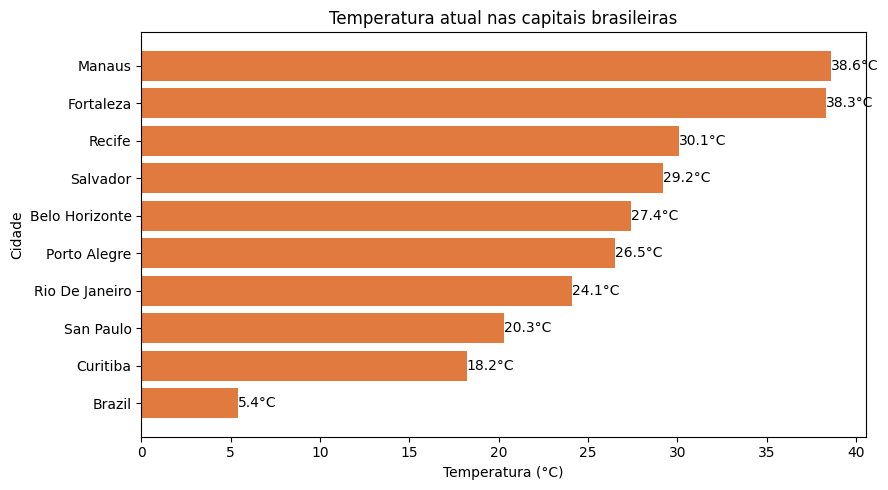

Arquivo clima_capitais.csv salvo.


In [6]:
# Etapa 3
df_ordenado = df.sort_values("Temperatura_C")

plt.figure(figsize=(9, 5))
barras = plt.barh(df_ordenado["Cidade"], df_ordenado["Temperatura_C"], color="#E07A3F")
plt.bar_label(barras, fmt="%.1f°C")
plt.title("Temperatura atual nas capitais brasileiras")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Cidade")
plt.tight_layout()
plt.show()

df.to_csv("clima_capitais.csv", index=False, encoding="utf-8-sig")
print("Arquivo clima_capitais.csv salvo.")